# 2次元データで比べる4つの分類器 / Four classifiers on simple 2D data

**目的 / Goal:** ロジスティック回帰、単純な決定木、ランダムフォレスト、非線形SVMの違いを、判定境界から理解します。
Understand logistic regression, a simple decision tree, random forest, and nonlinear SVM by comparing their decision boundaries.

今回は実測のWISDMではなく、scikit-learnで作る**人工データ**を使います。意味のあるセンサー値などではなく、入力は座標 `x1`, `x2` の2つだけです。ダウンロードは不要です。Google Colabにアップロードし、「ランタイム → すべてのセルを実行」で動きます。CPUで十分です。
We use **synthetic data generated with scikit-learn**, not WISDM measurements. Inputs are simply two coordinates, `x1` and `x2`. No data download is needed. Upload to Colab and choose **Runtime → Run all**. A CPU runtime is sufficient.

| データ / Dataset | 注目する点 / What to look for |
|---|---|
| Linear | ほぼ直線で分けられる基準例 / A baseline with an approximately linear separation |
| Moons | 2つの三日月。曲がった境界が必要 / Two interleaving moons requiring a curved boundary |
| Circles | 内側と外側の円。閉じた境界が必要 / Inner and outer circles requiring a closed boundary |

直線、軸に平行な分割、多数の木の組合せ、滑らかな非線形境界を見比べましょう。すべて同じ2特徴を使い、ロジスティック回帰への多項式特徴の追加などは行いません。結果はこの人工データと設定での比較であり、一般的な優劣ではありません。
Compare a straight boundary, axis-aligned splits, an ensemble of trees, and a smooth nonlinear boundary. All models use the same two features without polynomial expansion. Results describe these datasets and settings, not a universal ranking.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display
from sklearn.datasets import make_blobs, make_moons, make_circles
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.base import clone
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, make_scorer)

SEED = 42
OUT = Path('simple_classification_outputs')
OUT.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})

## 1. データを作る / Generate the data

各データは600点、2クラスです。70%をdevelopment（学習・交差検証）、30%を最終testに分けます。クラスの割合を保ち、4モデルで同じ分割を使います。以下の散布図にはdevelopmentだけを表示します。
Each dataset contains 600 points in two classes. We reserve 30% for testing and use 70% for development (training and cross-validation), preserving class proportions. All models use identical splits. The plots below show development data only.

実験では三日月や円の `noise` を増減してみてください。ノイズを増やすとクラスが重なり、複雑な境界でも完全には分けられなくなります。条件を変えたら、以降のセルをすべて再実行します。
Try changing `noise` for moons or circles. More noise causes class overlap that a complex boundary cannot necessarily resolve. After changing generation settings, rerun all subsequent cells.

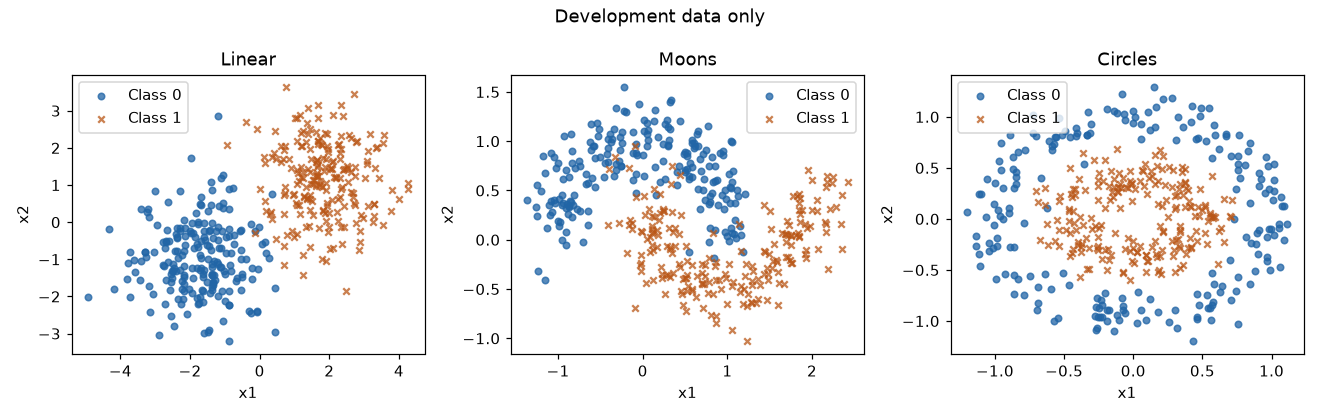

In [2]:
# データ生成の設定 / Data generation settings.
datasets = {
    'Linear': make_blobs(n_samples=600, centers=[[-1.7, -1.0], [1.7, 1.0]],
                        cluster_std=1.0, random_state=SEED),
    'Moons': make_moons(n_samples=600, noise=0.20, random_state=SEED),
    'Circles': make_circles(n_samples=600, factor=0.45, noise=0.12, random_state=SEED),
}
splits = {}
for name, (X, y) in datasets.items():
    X_dev, X_test, y_dev, y_test = train_test_split(
        X, y, test_size=0.30, stratify=y, random_state=SEED)
    splits[name] = (X_dev, X_test, y_dev, y_test)

def scatter_classes(ax, X, y, alpha=0.75):
    # 色と記号の両方で区別 / Distinguish classes by both color and marker.
    for label, marker, color in [(0, 'o', '#2165a6'), (1, 'x', '#b95616')]:
        ax.scatter(X[y == label, 0], X[y == label, 1], marker=marker,
                   color=color, s=18, alpha=alpha, label=f'Class {label}')
    ax.set(xlabel='x1', ylabel='x2')

fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
for ax, (name, (X_dev, _, y_dev, _)) in zip(axes, splits.items()):
    scatter_classes(ax, X_dev, y_dev)
    ax.set_title(name)
    ax.legend()
fig.suptitle('Development data only')
fig.tight_layout()
plt.show()

## 2. 同じ条件で4モデルを学習 / Train four models under shared conditions

- **Logistic regression:** ベースライン。2次元では直線の境界。 / Baseline with a straight boundary in two dimensions.
- **Simple tree:** 最大深さ3。少数の軸に平行な分割。 / Maximum depth three, using a small number of axis-aligned splits.
- **Random forest:** 200本の木。データの復元抽出と特徴量候補のランダム選択を使い、木のクラス確率を平均。 / 200 trees using bootstrap samples and random feature subsets, averaging class probabilities.
- **RBF SVM:** RBFカーネルによる非線形な境界。 / A nonlinear boundary learned with an RBF kernel.

ロジスティック回帰とSVMには標準化を適用します。平均・標準偏差は学習データだけから計算します。モデル設定は教材用に固定し、testに合わせた調整はしません。フォレストの各木は単純な決定木より深く成長できるため、この比較はアンサンブル化の効果だけを取り出した実験ではありません。
Logistic regression and SVM use scaling learned only from training data. Settings are fixed for teaching, not tuned on test data. Forest trees can grow deeper than the simple tree, so this comparison does not isolate the ensemble effect alone.

In [3]:
templates = {
    'Logistic regression': make_pipeline(StandardScaler(),
        LogisticRegression(C=1.0, max_iter=1000, random_state=SEED)),
    'Simple tree': DecisionTreeClassifier(max_depth=3, min_samples_leaf=5, random_state=SEED),
    'Random forest': RandomForestClassifier(n_estimators=200, min_samples_leaf=3,
        max_features='sqrt', random_state=SEED, n_jobs=-1),
    'RBF SVM': make_pipeline(StandardScaler(), SVC(C=3.0, gamma='scale', kernel='rbf')),
}
fitted = {}
for dataset, (X_dev, _, y_dev, _) in splits.items():
    for name, template in templates.items():
        fitted[dataset, name] = clone(template).fit(X_dev, y_dev)
print('Fitted 3 datasets × 4 models.')

Fitted 3 datasets × 4 models.


## 3. 判定境界を見比べる / Compare decision boundaries

背景色は予測クラス、黒線は境界、点はdevelopmentの観測クラスです。同じ行では軸の範囲をそろえています。点がない領域での境界の形もモデルによって異なりますが、そこに正解が確認されているわけではありません。
Background colors indicate predicted classes, black contours show boundaries, and points show development labels. All panels in a row share axis limits. Predictions in regions without observations are not evidence of verified behavior there.

特に、Circlesでロジスティック回帰が内側と外側を分けられるか、単純な木の境界がどれほど粗いか、フォレストとSVMがどのような形を作るかを見てください。
For Circles, examine whether logistic regression can separate inside from outside, how coarse the shallow tree's regions are, and how the forest and SVM form their boundaries.

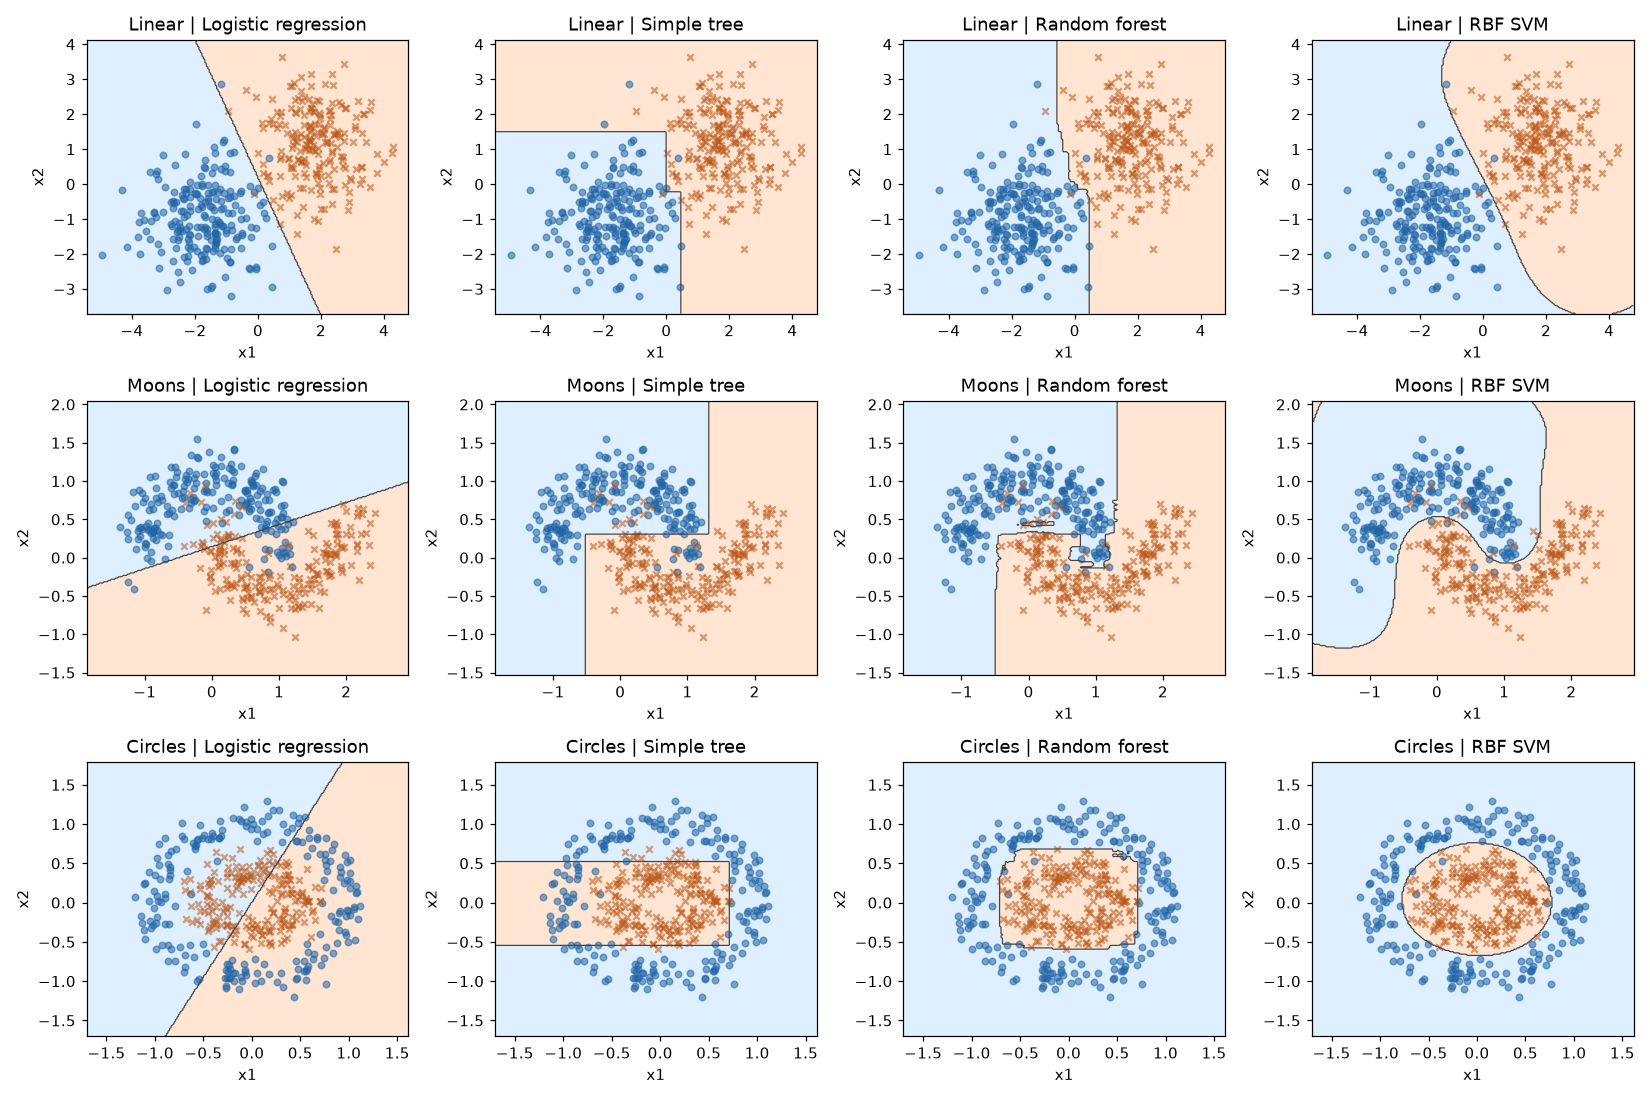

In [4]:
fig, axes = plt.subplots(3, 4, figsize=(15, 10))
for row, (dataset, (X_dev, _, y_dev, _)) in enumerate(splits.items()):
    lower, upper = X_dev.min(axis=0) - 0.5, X_dev.max(axis=0) + 0.5
    xx, yy = np.meshgrid(np.linspace(lower[0], upper[0], 220),
                         np.linspace(lower[1], upper[1], 220))
    grid = np.c_[xx.ravel(), yy.ravel()]
    for col, name in enumerate(templates):
        ax = axes[row, col]
        region = fitted[dataset, name].predict(grid).reshape(xx.shape)
        ax.contourf(xx, yy, region, levels=[-0.5, 0.5, 1.5], colors=['#deefff', '#ffe5d2'])
        ax.contour(xx, yy, region, levels=[0.5], colors='#444444', linewidths=0.8)
        scatter_classes(ax, X_dev, y_dev, alpha=0.55)
        ax.set(xlim=(lower[0], upper[0]), ylim=(lower[1], upper[1]))
        ax.set_title(f'{dataset} | {name}')
fig.tight_layout()
fig.savefig(OUT / 'decision_boundaries.png', dpi=180, bbox_inches='tight')
plt.show()

## 4. 三日月の決定木を読む / Read the decision tree for Moons

条件が真（≤）なら左、偽なら右に進みます。`samples` は全学習点のうちその節点に到達した割合、`value` はクラス0・1の割合、`class` は多数クラスです。数値は表示のため丸められています。
Follow the left branch if the condition is true (≤), otherwise the right branch. `samples` is the percentage of training points reaching the node, `value` gives class proportions in order 0, 1, and `class` is the majority class. Values are rounded for display.

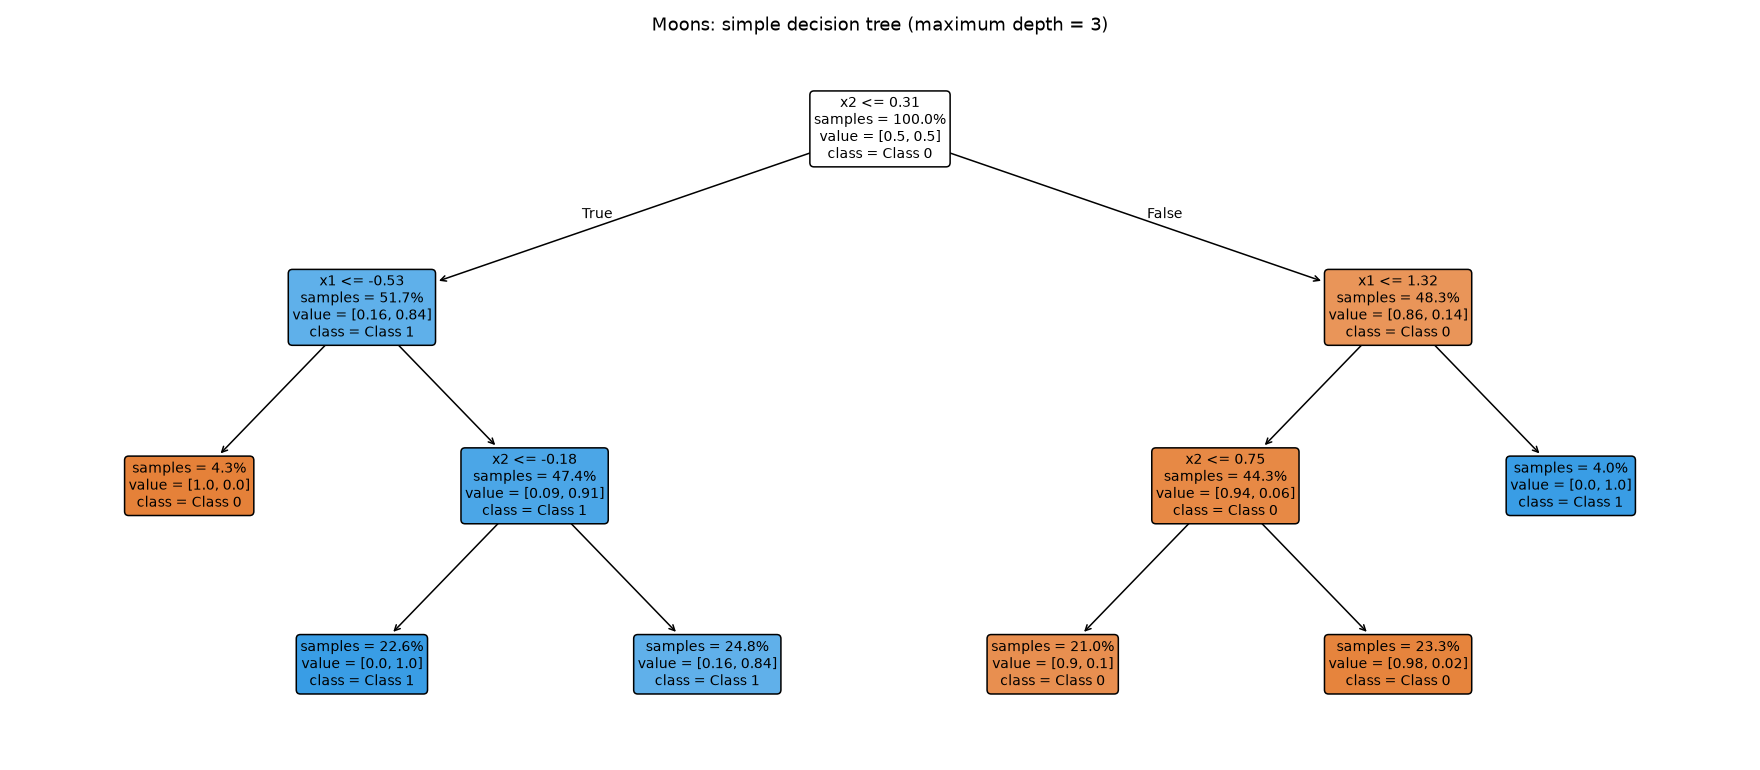

In [5]:
fig, ax = plt.subplots(figsize=(16, 7))
plot_tree(fitted['Moons', 'Simple tree'], feature_names=['x1', 'x2'],
          class_names=['Class 0', 'Class 1'], filled=True, rounded=True,
          proportion=True, impurity=False, precision=2, fontsize=9, ax=ax)
ax.set_title('Moons: simple decision tree (maximum depth = 3)')
fig.tight_layout()
fig.savefig(OUT / 'moons_tree.png', dpi=180, bbox_inches='tight')
plt.show()

## 5. 5分割交差検証 / Five-fold cross-validation

developmentだけで層化5分割交差検証を実行します。人工データの各点は独立に生成されており、人物のようなグループはないので、今回は `StratifiedKFold` を使います。4モデルで同じ分割を使い、各回で標準化も学習し直します。
We use five-fold stratified cross-validation on development data only. Unlike WISDM, these independently generated points have no participant groups, so we use `StratifiedKFold`. Models share the same folds, and scaling is refitted within each fold.

平均と標本標準偏差を表示します。標準偏差は信頼区間ではありません。クラス1を陽性として、適合率・再現率・F1を計算します。分母ゼロの場合の適合率などは、この実装では0とします。
We report means and sample standard deviations, not confidence intervals. Class 1 is positive for precision, recall, and F1. Undefined zero-denominator scores are reported as zero by convention.

Accuracy         Precision  ...  Recall      F1        
                                mean     std      mean  ...     std    mean     std
Dataset Model                                           ...                        
Linear  Logistic regression   0.9881  0.0119    0.9906  ...  0.0213  0.9880  0.0121
        Simple tree           0.9690  0.0181    0.9759  ...  0.0271  0.9687  0.0184
        Random forest         0.9881  0.0168    0.9904  ...  0.0213  0.9880  0.0170
        RBF SVM               0.9905  0.0100    0.9906  ...  0.0130  0.9905  0.0100
Moons   Logistic regression   0.8690  0.0469    0.8704  ...  0.0706  0.8679  0.0503
        Simple tree           0.9262  0.0330    0.9164  ...  0.0433  0.9269  0.0330
        Random forest         0.9524  0.0188    0.9709  ...  0.0310  0.9514  0.0191
        RBF SVM               0.9571  0.0181    0.9711  ...  0.0398  0.9562  0.0194
Circles Logistic regression   0.4619  0.0586    0.4593  ...  0.0973  0.4645  0.0785
        Simple tree           0.8476  0.0271    0.7879  ...  0.0426  0.8630  0.0201
        Random forest         0.9619  0.0319    0.9719  ...  0.0607  0.9609  0.0335
        RBF SVM               0.9810  0.0160    0.9733  ...  0.0130  0.9814  0.0150

[12 rows x 8 columns]

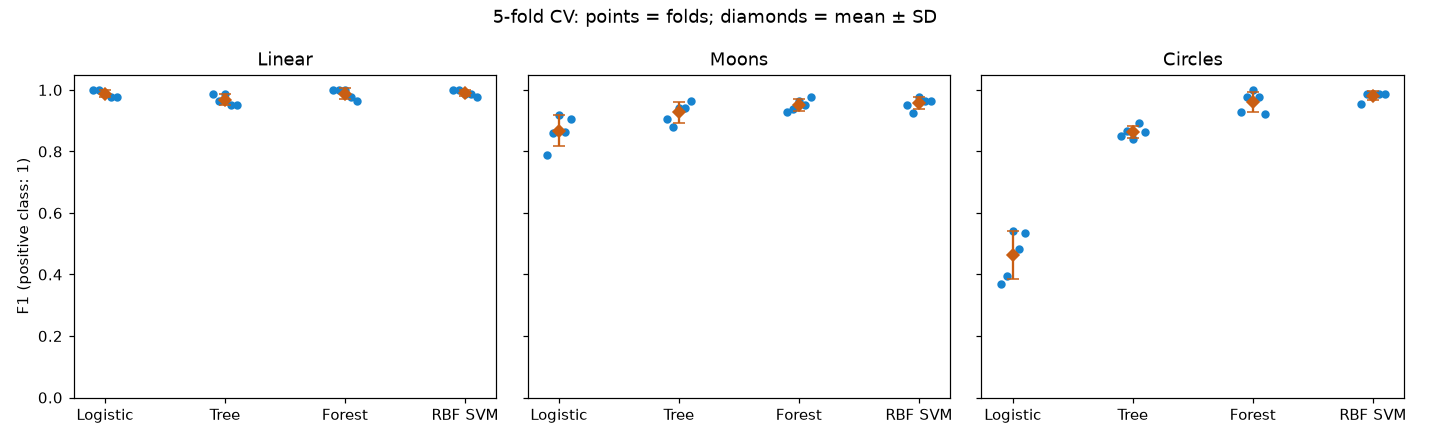

In [6]:
scoring = {
    'Accuracy': 'accuracy',
    'Precision': make_scorer(precision_score, zero_division=0),
    'Recall': make_scorer(recall_score, zero_division=0),
    'F1': make_scorer(f1_score, zero_division=0),
}
cv_rows = []
for dataset, (X_dev, _, y_dev, _) in splits.items():
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    folds = list(cv.split(X_dev, y_dev))
    for name, template in templates.items():
        scores = cross_validate(template, X_dev, y_dev, cv=folds, scoring=scoring,
                                error_score='raise')
        for fold in range(5):
            cv_rows.append({'Dataset': dataset, 'Model': name, 'Fold': fold + 1,
                            **{metric: scores['test_' + metric][fold] for metric in scoring}})
cv_results = pd.DataFrame(cv_rows)
cv_summary = cv_results.groupby(['Dataset', 'Model'], sort=False)[list(scoring)].agg(['mean', 'std'])
display(cv_summary.round(4))
cv_results.to_csv(OUT / 'cv_per_fold.csv', index=False)
cv_summary.to_csv(OUT / 'cv_mean_std.csv')

fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for ax, dataset in zip(axes, splits):
    for index, name in enumerate(templates):
        values = cv_results.loc[(cv_results.Dataset == dataset) & (cv_results.Model == name), 'F1']
        ax.scatter(index + np.linspace(-0.1, 0.1, 5), values, color='#1783cf', s=20)
        ax.errorbar(index, values.mean(), yerr=values.std(ddof=1), fmt='D', color='#c95e13', capsize=4)
    ax.set(title=dataset, xticks=range(4), xticklabels=['Logistic', 'Tree', 'Forest', 'RBF SVM'], ylim=(0, 1.05))
axes[0].set_ylabel('F1 (positive class: 1)')
fig.suptitle('5-fold CV: points = folds; diamonds = mean ± SD')
fig.tight_layout()
fig.savefig(OUT / 'cv_f1.png', dpi=180, bbox_inches='tight')
plt.show()

## 6. テスト評価と混同行列 / Test evaluation and confusion matrices

development全体で学習済みのモデルを、保持していたtestで評価します。ここではテスト結果に応じてモデル設定を変更しません。結果を見た後に設定を改善する場合、最終評価には新しい未使用データが必要です。
Models fitted on all development data are evaluated on the held-out test set. Settings are not changed based on these results. If test results guide later improvements, use fresh unused data for a final assessment.

**行＝実際、列＝予測、陽性＝クラス1**です。陽性を先に並べ、左上がTP、右上がFN、左下がFP、右下がTNになります。
**Rows = actual, columns = predicted, positive = class 1.** The positive class appears first: TP top left, FN top right, FP bottom left, TN bottom right.

- 正解率 / Accuracy = (TP + TN) / N
- 適合率 / Precision = TP / (TP + FP)
- 再現率 / Recall = TP / (TP + FN)
- F1 = 2TP / (2TP + FP + FN)

Dataset               Model  Accuracy     F1
 Linear Logistic regression    0.9667 0.9667
 Linear         Simple tree    0.9556 0.9556
 Linear       Random forest    0.9500 0.9503
 Linear             RBF SVM    0.9667 0.9667
  Moons Logistic regression    0.8667 0.8710
  Moons         Simple tree    0.9167 0.9198
  Moons       Random forest    0.9500 0.9503
  Moons             RBF SVM    0.9667 0.9674
Circles Logistic regression    0.4889 0.4831
Circles         Simple tree    0.8611 0.8649
Circles       Random forest    0.9833 0.9832
Circles             RBF SVM    0.9889 0.9889


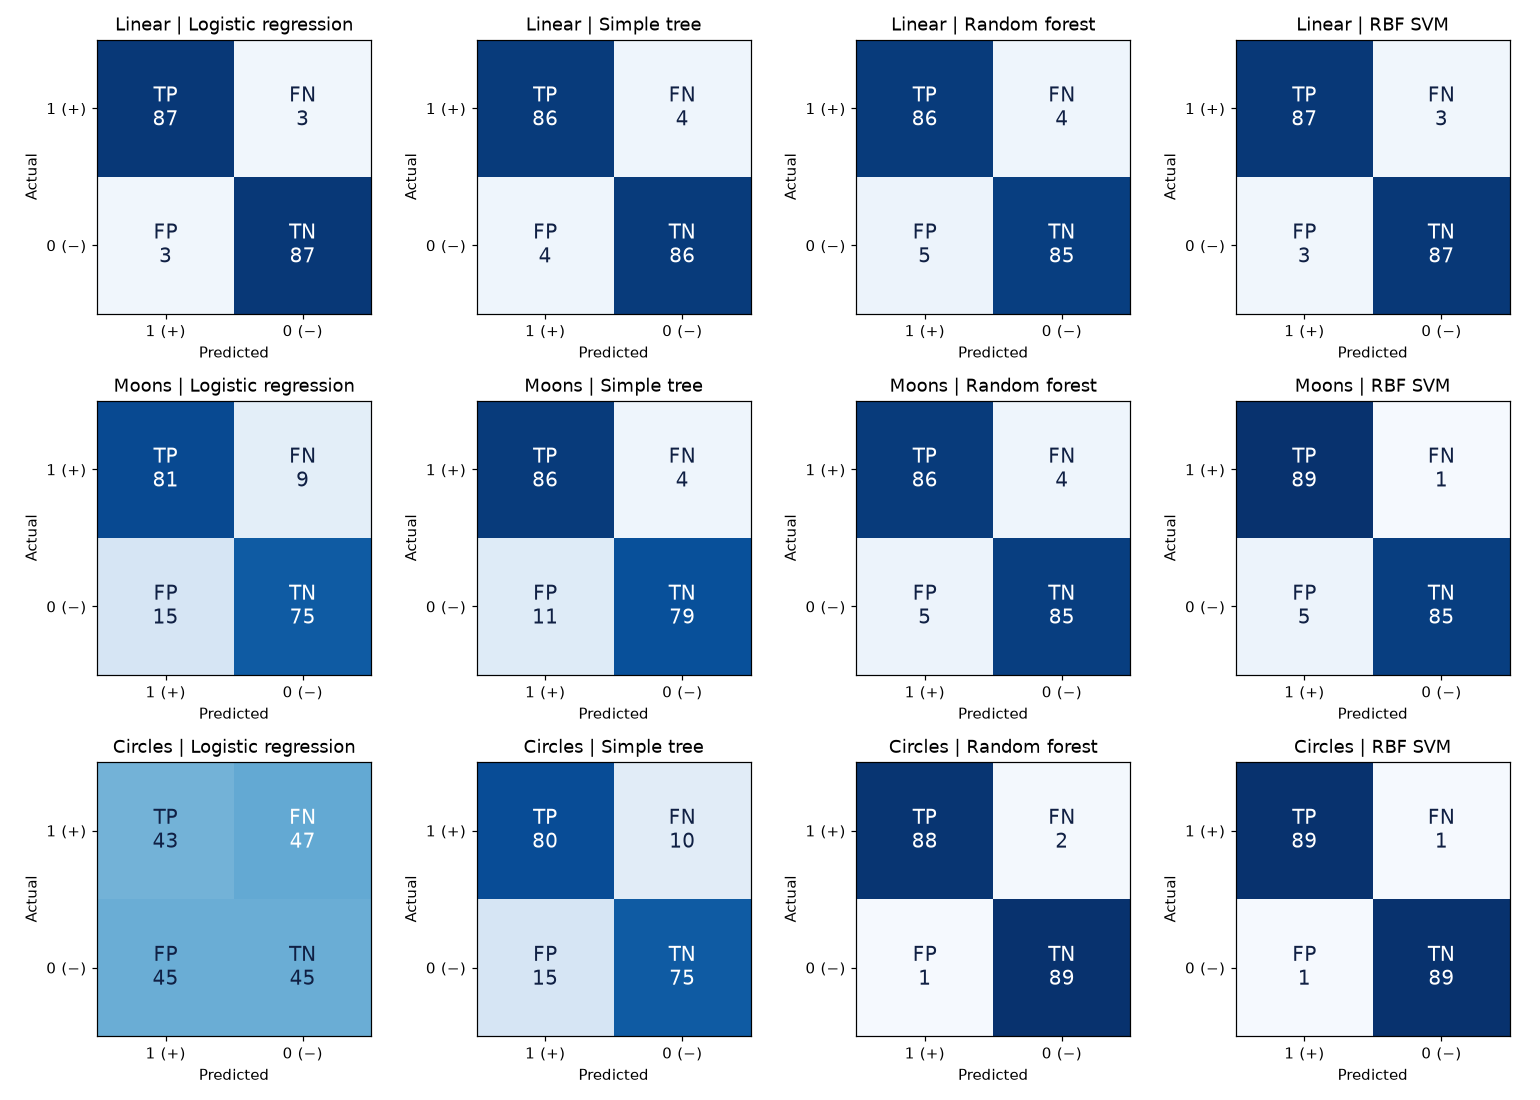

,Dataset,Model,Accuracy,Precision,Recall,F1,TP,FN,FP,TN
0,Linear,Logistic regression,0.9667,0.9667,0.9667,0.9667,87,3,3,87
1,Linear,Simple tree,0.9556,0.9556,0.9556,0.9556,86,4,4,86
2,Linear,Random forest,0.9500,0.9451,0.9556,0.9503,86,4,5,85
3,Linear,RBF SVM,0.9667,0.9667,0.9667,0.9667,87,3,3,87
4,Moons,Logistic regression,0.8667,0.8438,0.9000,0.8710,81,9,15,75
5,Moons,Simple tree,0.9167,0.8866,0.9556,0.9198,86,4,11,79
6,Moons,Random forest,0.9500,0.9451,0.9556,0.9503,86,4,5,85
7,Moons,RBF SVM,0.9667,0.9468,0.9889,0.9674,89,1,5,85
8,Circles,Logistic regression,0.4889,0.4886,0.4778,0.4831,43,47,45,45
9,Circles,Simple tree,0.8611,0.8421,0.8889,0.8649,80,10,15,75


Model,Logistic regression,RBF SVM,Random forest,Simple tree
Dataset,,,,
Circles,0.489,0.989,0.983,0.861
Linear,0.967,0.967,0.950,0.956
Moons,0.867,0.967,0.950,0.917


In [7]:
test_rows = []
fig, axes = plt.subplots(3, 4, figsize=(14, 10))
for row, (dataset, (_, X_test, _, y_test)) in enumerate(splits.items()):
    for col, name in enumerate(templates):
        prediction = fitted[dataset, name].predict(X_test)
        cm = confusion_matrix(y_test, prediction, labels=[1, 0])
        tp, fn, fp, tn = cm.ravel()
        assert cm.sum() == len(y_test)
        metrics = {'Accuracy': accuracy_score(y_test, prediction),
                   'Precision': precision_score(y_test, prediction, zero_division=0),
                   'Recall': recall_score(y_test, prediction, zero_division=0),
                   'F1': f1_score(y_test, prediction, zero_division=0)}
        test_rows.append({'Dataset': dataset, 'Model': name, **metrics,
                          'TP': tp, 'FN': fn, 'FP': fp, 'TN': tn})
        ax = axes[row, col]
        ax.imshow(cm, cmap='Blues', vmin=0, vmax=len(y_test) / 2)
        for i in range(2):
            for j in range(2):
                term = [['TP', 'FN'], ['FP', 'TN']][i][j]
                ax.text(j, i, f'{term}\n{cm[i, j]}', ha='center', va='center', fontsize=13,
                        color='white' if cm[i, j] > len(y_test) / 4 else '#102044')
        ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=['1 (+)', '0 (−)'],
               yticklabels=['1 (+)', '0 (−)'], xlabel='Predicted', ylabel='Actual',
               title=f'{dataset} | {name}')
fig.tight_layout()
fig.savefig(OUT / 'test_confusion_matrices.png', dpi=180, bbox_inches='tight')
plt.show()
test_results = pd.DataFrame(test_rows)
display(test_results.round(4))
print(test_results[['Dataset', 'Model', 'Accuracy', 'F1']].round(4).to_string(index=False))
test_results.to_csv(OUT / 'test_metrics.csv', index=False)
display(test_results.pivot(index='Dataset', columns='Model', values='Accuracy').round(3))

## 7. 講義で考える問い / Discussion questions

1. Linearでは、複雑なモデルにすると必ず改善しますか？ / Does a more complex model always help on Linear?
2. Circlesで、直線の境界では何ができませんか？ / What can a straight boundary not express on Circles?
3. 決定木の深さを1、3、8に変えると、境界と交差検証の結果はどう変わりますか？ / How do boundaries and CV results change at tree depths 1, 3, and 8?
4. フォレストはSVMのような滑らかな境界になりますか？ / Does the forest produce a smooth boundary like SVM?
5. SVMのCやgammaを変えると、境界の細かさはどう変わりますか？ / How do C and gamma affect SVM boundary complexity?

モデルの複雑さを変える実験はdevelopmentと交差検証で比較してください。人工データなので、別の乱数seedで新しい評価データを生成する実験もできます。同じtestを繰り返し見て最適化した結果と、新しいデータでの評価を区別しましょう。
Compare complexity settings using development data and cross-validation. Because these are synthetic datasets, you can generate fresh evaluation data with another seed. Distinguish repeated tuning against the same test set from evaluation on new data.

画像とCSVは `simple_classification_outputs` に保存されます。説明・コメントは日英併記、図中の表記は英語です。
Figures and CSV files are saved in `simple_classification_outputs`. Explanations and comments are bilingual; plot labels are English.

In [8]:
import shutil
# 結果をまとめて保存 / Package the results.
print(shutil.make_archive('simple_classification_results', 'zip', OUT))

C:\Users\hamag\Dropbox\000main\00MYDOC\00横国\01 講義関連\○知能システム論\R08\classification_demo\simple_test_run\simple_classification_results.zip
